# 05 · Thompson sampling and MMR

Maths unit **M7**. Read `rec/r4_thompson.py` and `rec/rerank.py`.

R4 keeps a posterior over R3's weights and serves one draw from it per batch, so it explores where it is unsure. This notebook checks M7 by hand, shows the posterior narrowing as labels accumulate, and reports the finding behind DECISIONS #25: on this noisy simulated user, one draw's noise outweighs the signal at the specified temperature.

**Everything below that involves a user is SIMULATED** (`eval/sim.py`). Real labels only exist once Alen swipes.

In [1]:
import glob, json, time
import numpy as np
import matplotlib.pyplot as plt

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings

state = AppState(get_settings())
state.load()
features = state.require_features()
print(f"{len(features):,} pool images loaded")

Archive ladder reached rule 5: no external drive and only 42.7 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


50,000 pool images loaded


## 1 · M7: the uncertain image wins 37% of the time

In [2]:
from scipy.stats import norm
from visualtaste.rec.rerank import mmr_value

print("P(B beats A) =", round(norm.cdf((0.50 - 0.60) / np.hypot(0.05, 0.30)), 3))
draws = np.random.default_rng(0)
print("simulated    =", round(float((draws.normal(0.5, 0.3, 100_000) > draws.normal(0.6, 0.05, 100_000)).mean()), 3))
print("MMR: b ->", round(mmr_value(0.88, 0.95), 3), " c ->", round(mmr_value(0.80, 0.30), 3), " (c is picked)")

P(B beats A) = 0.371
simulated    = 0.372
MMR: b -> 0.331  c -> 0.47  (c is picked)


## 2 · The posterior narrows as labels accumulate

Fit R4 on the first N labels of a cached simulated session (phase11_h4, S1, R4 as the policy), and measure how far one posterior draw moves the logits.

  100 labels  lambda 10     MAP logit sd 0.054   one draw's deviation sd 0.371


  200 labels  lambda 3      MAP logit sd 0.125   one draw's deviation sd 0.462


  400 labels  lambda 3      MAP logit sd 0.097   one draw's deviation sd 0.326


  700 labels  lambda 1      MAP logit sd 0.205   one draw's deviation sd 0.395


 1000 labels  lambda 1      MAP logit sd 0.178   one draw's deviation sd 0.329


Text(0.5, 1.0, 'Posterior noise vs signal (tau_post = 1)')

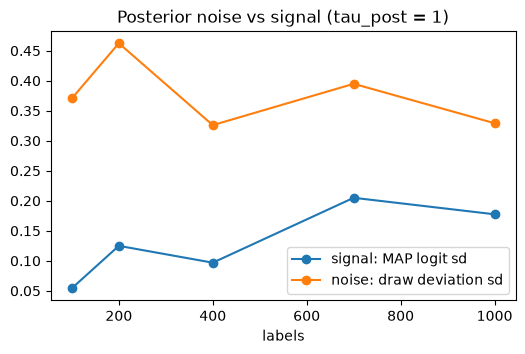

In [3]:
from visualtaste.eval.study import SeedResult, labels_from_history
from visualtaste.rec.labels import label_weights
from visualtaste.rec.r4_thompson import ThompsonRecommender, sample_weights

history = SeedResult.from_json(open(sorted(glob.glob("../data/eval/phase11_h4/S1_semantic/r4/seed_*.json"))[0], encoding="utf-8").read())
rows = []
for n in (100, 200, 400, 700, 1000):
    model = ThompsonRecommender().fit(labels_from_history(history.image_ids[:n], history.actions[:n], label_weights(0.25), False), features)
    signal = model.logits(features).std()
    W = sample_weights(model.w, model.L, np.random.default_rng(0), draws=20)
    noise = (model.pool_logits(features, W) - model.logits(features)[:, None]).std()
    rows.append((n, model.lam, signal, noise))
    print(f"{n:>5} labels  lambda {model.lam:<6g} MAP logit sd {signal:.3f}   one draw's deviation sd {noise:.3f}")
n, lam, signal, noise = map(np.array, zip(*rows))
plt.figure(figsize=(6, 3.5)); plt.plot(n, signal, "o-", label="signal: MAP logit sd"); plt.plot(n, noise, "o-", label="noise: draw deviation sd")
plt.xlabel("labels"); plt.legend(); plt.title("Posterior noise vs signal (tau_post = 1)")

Measured on this history (2026-11-01): the signal grows from 0.05 to about 0.2 as lambda relaxes, but one draw's deviation hardly falls at all over 1,000 labels (0.33-0.46) and stays two to seven times larger. One draw then ranks the pool almost at random, which is why R4 at tau = 1 keeps coverage near 100% and the like rate near R0's (DECISIONS #25). The sensitivity study (`phase10_sensitivity` in EVALUATION.md) measures smaller temperatures.

## 3 · Exploration against exploitation over time

From the cached phase10_h3 sessions: like rate and coverage of the last 500 cards, R3 against R4, averaged over seeds.

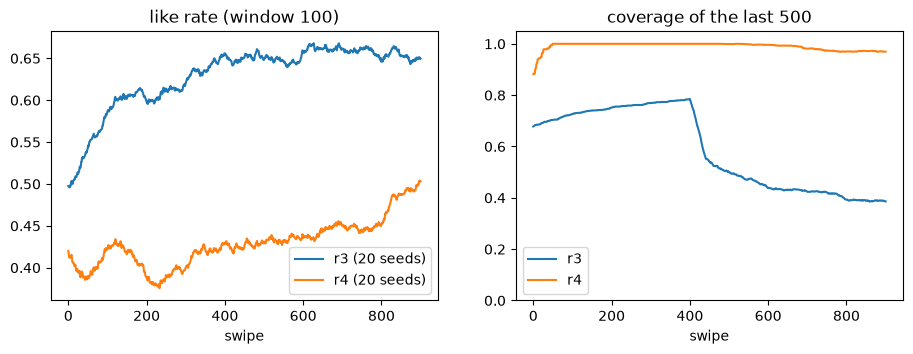

In [4]:
def curves(spec, window=100):
    like, cover = [], []
    for path in sorted(glob.glob(f"../data/eval/phase10_h3/S1_semantic/{spec}/seed_*.json")):
        r = SeedResult.from_json(open(path, encoding="utf-8").read())
        liked = np.isin(r.actions, ["like", "save"]).astype(float)
        clusters = np.asarray(features.cluster64)[features.positions(r.image_ids)]
        like.append(np.convolve(liked, np.ones(window) / window, mode="valid"))
        cover.append([len(set(clusters[max(0, i - 500):i])) / 64 for i in range(window, len(clusters) + 1)])
    return np.mean(like, axis=0), np.mean(cover, axis=0), len(like)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for spec in ("r3", "r4"):
    like, cover, seeds = curves(spec)
    axes[0].plot(like, label=f"{spec} ({seeds} seeds)"); axes[1].plot(cover, label=spec)
axes[0].set(title="like rate (window 100)", xlabel="swipe"); axes[1].set(title="coverage of the last 500", xlabel="swipe", ylim=(0, 1.05))
axes[0].legend(); axes[1].legend()